# Data sanity check

Quick check of the preprocessed data of the three datasets: class distribution, a typical epoch of each stage, median power spectrum per stage, and whole-night overviews of recordings flagged in earlier issues.

All functions live in `src/data/figures.py`; `python -m src.data.figures` writes the same files to `outputs/figures/` without the notebook.

In [1]:
# Run from the repository root, whatever folder Jupyter started in
import os
import sys
from pathlib import Path

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(root)
sys.path.insert(0, str(root))

%matplotlib inline
import matplotlib.pyplot as plt

from src.data import figures as F
from src.data.format import STAGES

F.thesis_style()

## 1. Load

Each recording is loaded twice (filter off and on, always robust-scaled); per-epoch spectra are computed with Welch (10-s windows). Takes a few minutes.

In [2]:
all_stats = [F.collect_dataset(d) for d in F.DATASETS]
for s in all_stats:
    print(f"{F.NAMES[s['dataset']]:>9}: {len(s['paths'])} recordings, {s['counts'].sum()} epochs")

Sleep-EDF: 39 recordings, 42307 epochs
    ISRUC: 20 recordings, 18276 epochs
      HMC: 20 recordings, 18968 epochs


## 2. Class distribution

Check: proportions match the loader logs; N1 is the minority class everywhere; the stage mix differs between datasets.

Sleep-EDF: W 19.6% | N1 6.6% | N2 42.1% | N3 13.5% | REM 18.2%
    ISRUC: W 31.2% | N1 12.7% | N2 26.2% | N3 17.8% | REM 12.2%
      HMC: W 18.0% | N1 10.4% | N2 37.0% | N3 18.1% | REM 16.5%


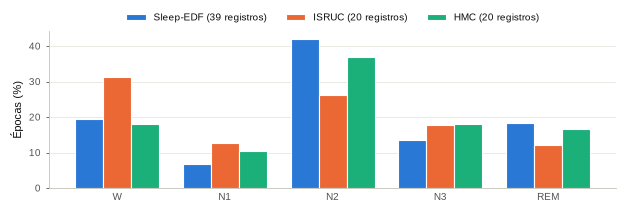

In [3]:
for s in all_stats:
    c = s["counts"]
    print(f"{F.NAMES[s['dataset']]:>9}: " + " | ".join(f"{STAGES[k]} {100 * c[k] / c.sum():.1f}%" for k in range(len(STAGES))))

F.write_class_tables(all_stats)
fig = F.plot_class_distribution(all_stats)
F.save_figure(fig, "class_distribution")
plt.show()

## 3. Typical epoch of each stage

Per dataset and stage, the epoch whose spectrum (filter on, 0.5-30 Hz) is closest to the stage median. Signal as the model sees it: filtered and robust-scaled (IQR units), same scale in every panel.

Check: W fast activity, N2 spindles / K-complexes, N3 large slow waves, REM low-amplitude mixed activity. An epoch that looks like an artifact points to a recording worth inspecting.

Sleep-EDF {'W': 'SC4072 epoch 589', 'N1': 'SC4192 epoch 2348', 'N2': 'SC4061 epoch 1189', 'N3': 'SC4131 epoch 1229', 'REM': 'SC4002 epoch 1506'}
ISRUC {'W': 'isruc_13 epoch 176', 'N1': 'isruc_18 epoch 178', 'N2': 'isruc_15 epoch 753', 'N3': 'isruc_15 epoch 299', 'REM': 'isruc_18 epoch 477'}
HMC {'W': 'SN020 epoch 705', 'N1': 'SN004 epoch 927', 'N2': 'SN021 epoch 787', 'N3': 'SN007 epoch 231', 'REM': 'SN017 epoch 823'}


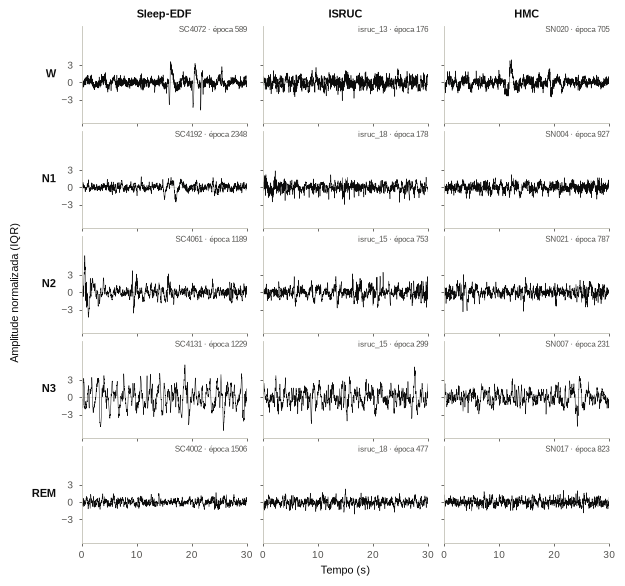

In [4]:
examples = {s["dataset"]: F.typical_epochs(s) for s in all_stats}
F.write_example_table(examples)
for d, ex in examples.items():
    print(F.NAMES[d], {STAGES[k]: f"{e['recording_id']} epoch {e['epoch_idx']}" for k, e in ex.items()})

fig = F.plot_example_epochs(examples)
F.save_figure(fig, "example_epochs")
plt.show()

## 4. Median power spectrum per stage

Top row filter off, bottom row filter on (vertical lines at 0.3 and 35 Hz); log frequency axis; power of the robust-scaled signal in dB.

Check: each stage keeps its spectral signature (N3 low-frequency peak, alpha in W); where the datasets differ with and without the filter.

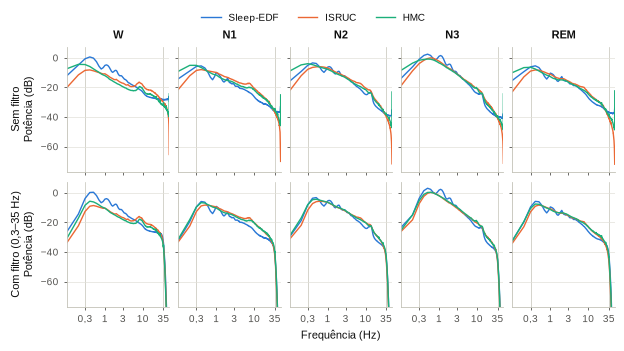

In [5]:
fig = F.plot_psd_per_stage(all_stats)
F.save_figure(fig, "psd_per_stage")
plt.show()

## 5. Flagged recordings

Hypnogram, per-epoch p99 of |x| (µV, saved signal), and per-epoch share of power below 0.3 Hz and above 35 Hz. SN018 (large artifacts), SC4111 (high-frequency noise), isruc_6 and isruc_13 (mostly wake), with SN002, SC4001 and isruc_2 for comparison.

Check: is a problem confined to a block of epochs or spread over the night, and does the signal follow the labels?

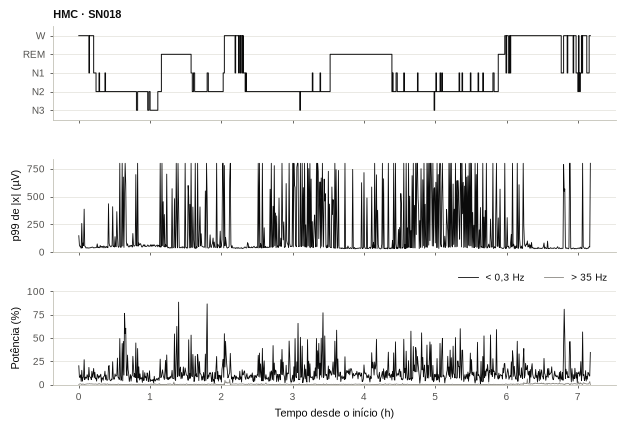

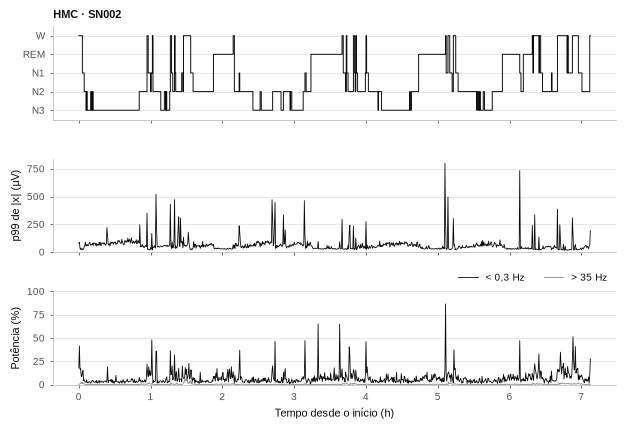

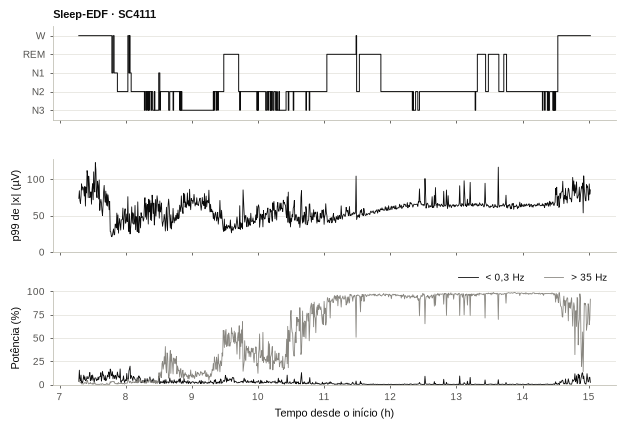

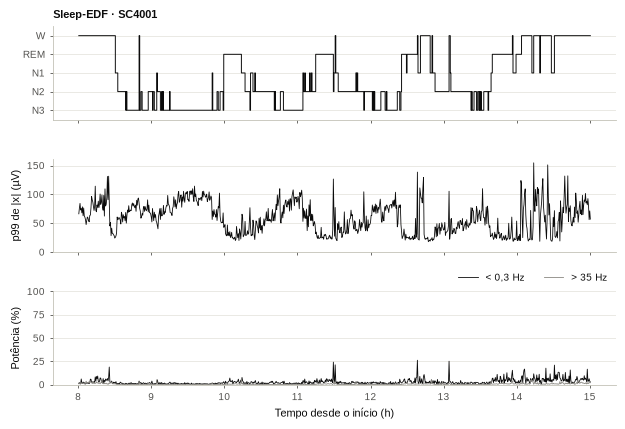

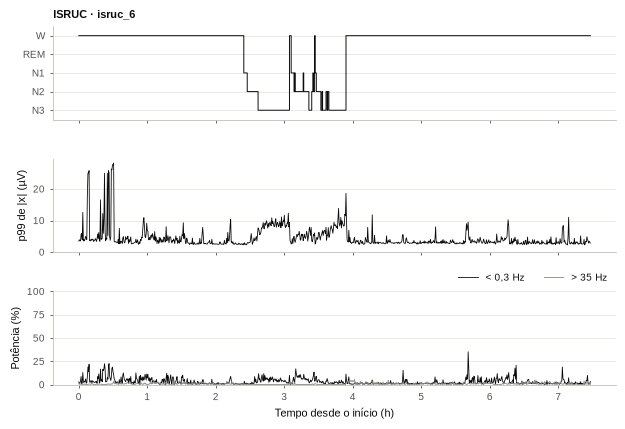

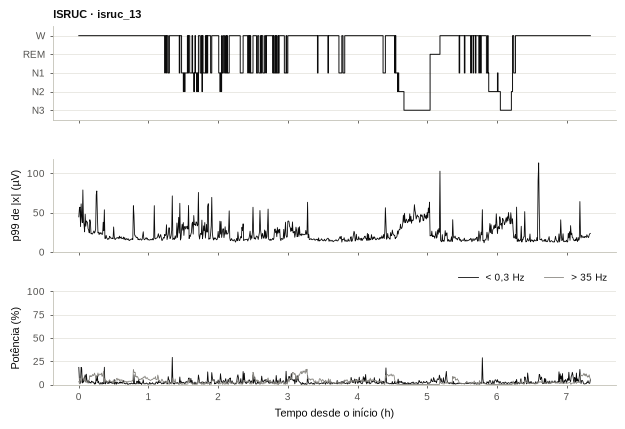

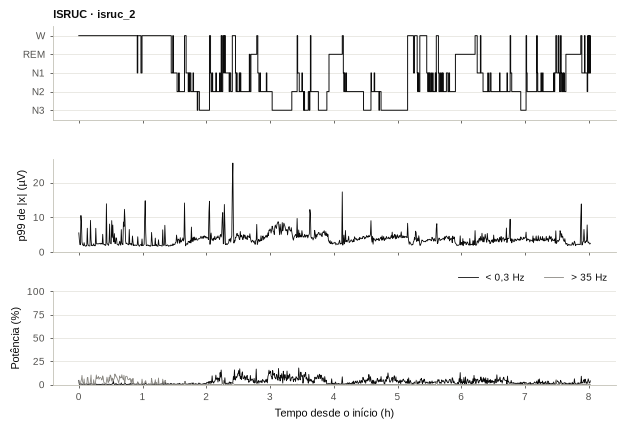

In [6]:
for dataset, recording_id in F.FLAGGED:
    if not any(p.stem == recording_id for p in F.recording_paths(dataset)):
        print(f"{recording_id}: not found")
        continue
    fig = F.plot_recording_overview(dataset, recording_id)
    F.save_figure(fig, recording_id, F.OUT / "diagnostics")
    plt.show()